In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)
from sklearn.model_selection import GridSearchCV
from IPython.display import display


In [2]:

df = pd.read_csv("classification_escalation.csv")

print("Dataset shape:", df.shape)

display(df.head())

print("\nDataset information:")
df.info()

print("\nTarget prevalence:")
print(df["escalated"].value_counts(normalize=True))


Dataset shape: (900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB

Target prevalence:
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


In [3]:

print("Missing values per column:")
print(df.isnull().sum())

print("\nMissing value percentages:")
print((df.isnull().mean() * 100).round(2))


Missing values per column:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Missing value percentages:
complexity_score          0.00
team_experience_years     3.44
priority                  2.00
channel                   0.00
customer_tenure_months    2.44
escalated                 0.00
dtype: float64


In [4]:

X = df.drop(columns=["escalated"])
y = df["escalated"]

print("Predictors shape:", X.shape)
print("Target shape:", y.shape)


Predictors shape: (900, 5)
Target shape: (900,)


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))


Training data: (675, 5)
Testing data: (225, 5)

Training target distribution:
escalated
0    0.792593
1    0.207407
Name: proportion, dtype: float64

Testing target distribution:
escalated
0    0.795556
1    0.204444
Name: proportion, dtype: float64


In [6]:

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['complexity_score', 'team_experience_years', 'customer_tenure_months']
Categorical features: ['priority', 'channel']


In [7]:

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created successfully.")

Numerical preprocessing pipeline created successfully.


In [8]:

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
print("Categorical preprocessing pipeline created successfully.")

Categorical preprocessing pipeline created successfully.


In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)
print("Combined preprocessor created successfully.")

Combined preprocessor created successfully.


In [10]:

models = {
    "Majority Baseline": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Linear Discriminant Analysis": LinearDiscriminantAnalysis(),

    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15)
}

print("Four classification models defined successfully.")

for name in models:
    print("-", name)


Four classification models defined successfully.
- Majority Baseline
- Logistic Regression
- Linear Discriminant Analysis
- k-NN (k=15)


In [11]:

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        )
    }

    if hasattr(pipeline, "predict_proba"):
        y_prob = pipeline.predict_proba(X_test)[:, 1]
        row["ROC-AUC"] = roc_auc_score(y_test, y_prob)
    else:
        row["ROC-AUC"] = np.nan

    trained_models[name] = pipeline
    results.append(row)

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,Linear Discriminant Analysis,0.8222,0.75,0.1957,0.3103,0.8090
3,k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


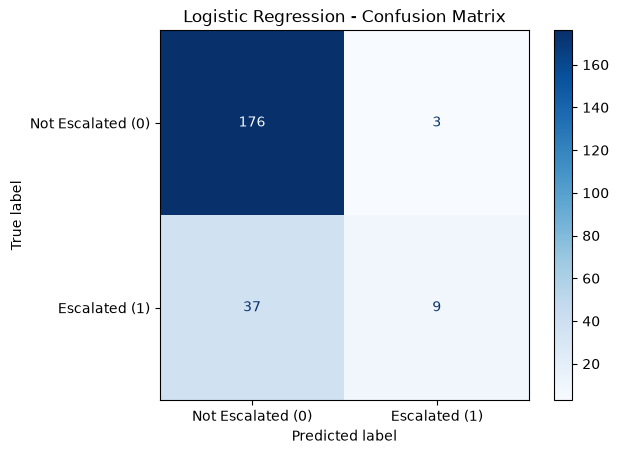

Confusion Matrix:
[[176   3]
 [ 37   9]]


In [12]:
logistic_model = trained_models["Logistic Regression"]

y_pred_logistic = logistic_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_logistic)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Escalated (0)", "Escalated (1)"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

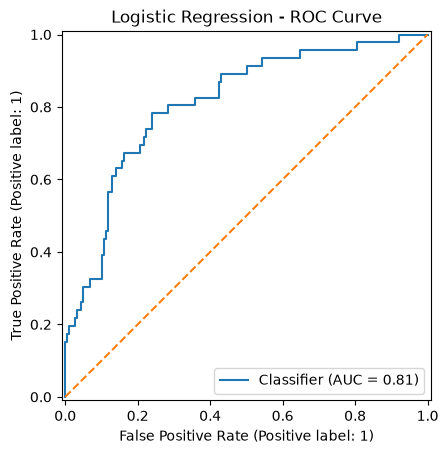

In [13]:

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_logistic
)

plt.title("Logistic Regression - ROC Curve")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.show()


In [14]:

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob_logistic >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1,FP,FN
0,0.2,0.4286,0.7826,0.5538,48,10
1,0.3,0.5490,0.6087,0.5773,23,18
2,0.4,0.5714,0.2609,0.3582,9,34
3,0.5,0.7500,0.1957,0.3103,3,37
4,0.6,1.0000,0.0652,0.1224,0,43
5,0.7,0.0000,0.0000,0.0000,0,46


In [15]:
threshold_df["Cost"] = (
    5 * threshold_df["FN"] +
    threshold_df["FP"]
)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1,FP,FN,Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230


In [16]:
best_threshold_row = threshold_df.loc[
    threshold_df["Cost"].idxmin()
]

print("Best threshold:")
print(best_threshold_row)


Best threshold:
Threshold     0.200000
Precision     0.428571
Recall        0.782609
F1            0.553846
FP           48.000000
FN           10.000000
Cost         98.000000
Name: 0, dtype: float64


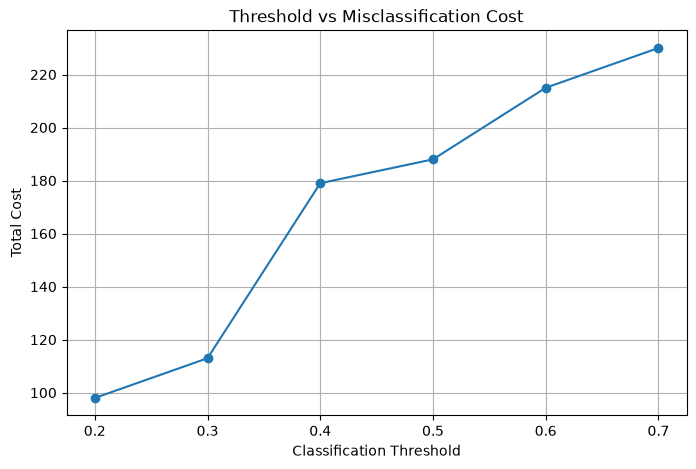

In [17]:

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Cost"],
    marker="o"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Total Cost")
plt.title("Threshold vs Misclassification Cost")
plt.grid(True)

plt.show()


In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [19]:
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])


In [20]:
param_grid = {
    "classifier__n_neighbors": [5, 9, 15, 21, 31]
}

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__n_neighbors': [5, 9, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of inf

In [21]:
print("Best k:", grid_search.best_params_)

print("Best cross-validation F1:")
print(grid_search.best_score_)

cv_results = pd.DataFrame(grid_search.cv_results_)

display(
    cv_results[
        [
            "param_classifier__n_neighbors",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].round(4)
)


Best k: {'classifier__n_neighbors': 5}
Best cross-validation F1:
0.24329611908559276


,param_classifier__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,5,0.2433,0.0946,1
1,9,0.1976,0.0652,2
2,15,0.1596,0.0655,3
3,21,0.1458,0.0564,4
4,31,0.1122,0.0397,5


In [22]:
best_knn = grid_search.best_estimator_

best_knn_predictions = best_knn.predict(X_test)

print(classification_report(
    y_test,
    best_knn_predictions,
    zero_division=0
))


              precision    recall  f1-score   support

           0       0.81      0.96      0.88       179
           1       0.46      0.13      0.20        46

    accuracy                           0.79       225
   macro avg       0.64      0.55      0.54       225
weighted avg       0.74      0.79      0.74       225



Why is accuracy alone potentially misleading?

Accuracy alone can be misleading because our dataset is imbalanced. Approximately 79.33% of the tickets are not escalated, while only 20.67% are escalated. This means a model could predict every ticket as not escalated and still achieve around 79.33% accuracy without identifying a single escalated ticket. Therefore, accuracy does not tell us how well the model identifies tickets that actually need escalation. We should also consider precision, recall, F1-score, and ROC-AUC to evaluate the model properly.

● Which classifier has the strongest recall? Which has the strongest precision/F1?

Based on the model comparison, Logistic Regression and Linear Discriminant Analysis (LDA) achieved the strongest recall, both with 19.57%. They also achieved the highest precision of 75% and the highest F1-score of 0.3103.

Logistic Regression achieved the highest ROC-AUC of 0.8111, slightly outperforming LDA, which achieved 0.8090. Therefore, Logistic Regression performed slightly better overall in distinguishing between escalated and non-escalated tickets.

● What changes when the threshold is lowered?

When the classification threshold is lowered, the model becomes more likely to classify a ticket as escalated. This means it can identify more tickets that actually need escalation, increasing recall and reducing false negatives. However, it may also incorrectly classify some non-escalated tickets as escalated, increasing false positives and potentially reducing precision.

For example, when we lowered the threshold from 0.50 to 0.20, recall increased from 19.57% to 78.26%. This means the model identified many more actual escalated tickets, but it also produced more false alarms.

● Which threshold minimizes 5×FN + FP on the test set, and why might this estimate be
optimistic if used repeatedly for tuning?

The threshold of 0.20 minimizes the cost among the six tested thresholds, giving a total cost of 98.

Using our cost function:     Cost=5(FN)+FP
At threshold 0.20, we have 10 false negatives and 48 false positives.Cost=5(10)+48=98
This threshold gives the lowest cost because a false negative is five times more expensive than a false positive. In our scenario, missing a ticket that actually needs escalation is more serious than incorrectly flagging a ticket.

However, this result might be optimistic because we used the test set to compare multiple thresholds and selected the one with the lowest cost. Repeatedly using the test set for tuning can lead to overestimating the model's performance. A better approach is to select the threshold using validation data or cross-validation and use the test set only for final evaluation.

● Explain prior, likelihood, posterior, and evidence using the ticket scenario.

Prior: The probability that a ticket will be escalated before considering its individual details. In our dataset, approximately 20.67% of tickets are escalated.
Likelihood: The probability of observing certain ticket details, such as high complexity or high priority, given that the ticket is escalated.
Evidence: The overall probability of observing those ticket details, whether the ticket is escalated or not.
Posterior: The updated probability that a ticket will be escalated after considering its details.

For example, if a ticket has high complexity and high priority, we can use this information to estimate how likely it is to be escalated.

Bayes' theorem combines these probabilities to calculate the posterior probability.

● With posterior P(escalated|x)=0.30, false-positive cost 1 and false-negative cost 5, compare
the expected cost of escalating and not escalating. Derive the cost-sensitive threshold.

The probability of escalation is 0.30, meaning there is a 30% chance the ticket needs escalation and a 70% chance it does not.
- Escalating: 0.70*1=0.70
- Not escalating: 0.30*5=1.50
Since 0.70 is lower than 1.50, we should escalate the ticket.
The cost-sensitive threshold is:p> CFP/CFP+CFN= 1/1+5 = 0.1667
Therefore, we should escalate tickets when their predicted probability is greater than 16.67%.
To derive the cost-sensitive threshold, let \(p\) represent the probability of escalation.
                    (1-p)*1 < p*5
                      1-p<5p
                       1<6p
                       p>1/6
                      p>0.1667

Therefore, the cost-sensitive threshold is approximately 0.167 (16.67%). If the predicted probability of escalation is greater than this value, we should escalate the ticket because doing so has a lower expected cost

● Which model would you recommend for deployment, and what further checks are required?

I would recommend Logistic Regression because it achieved the highest ROC-AUC of 0.8111 among the models tested. However, its recall at the default threshold was low, so I would consider lowering the threshold to identify more escalated tickets.

Before deployment, I would test the model using new data, check its prediction accuracy, monitor its performance over time, protect customer information, and ensure that important decisions can still be reviewed by humans.